# EDA — Encuadre 1: subregistro delictivo ajustado por alcaldía (CDMX)

**Reunión inicial de encuadres · 14 sep 2026 · Alcance exclusivamente exploratorio.**

**Pregunta del encuadre:** ¿Cómo varía el subregistro delictivo estimado en la CDMX entre alcaldías, y qué factores sociodemográficos explican esa variación?

Este notebook **no** modela ni construye el estimador. Su objetivo es responder, con los datos ya descargados:

1. ¿Qué contiene cada fuente, con qué grano, periodo y calidad?
2. ¿Aguanta ENVIPE una desagregación por alcaldía? (el pendiente crítico del encuadre)
3. ¿Hay covariables del Censo a nivel AGEB para la hipótesis (escolaridad, hacinamiento, confianza)?
4. ¿Se pueden unir las fuentes sin fricción?
5. Dada la naturaleza de los datos, ¿conviene ajustar o cambiar el encuadre?

Al final: semáforo por objetivo, encuadres alternativos y preguntas probables de sinodales.

In [1]:
import glob, io, re, unicodedata, warnings, zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 180, "display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd() if (Path.cwd() / "carpetas-datos").exists() else Path.cwd().parent
ENVIPE = ROOT / "conjunto_de_datos_envipe_2025_csv"
RNG = np.random.default_rng(2026)

def norm(s):
    # Normaliza nombres (sin acentos, mayúsculas, espacios simples) para joins entre fuentes
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s.upper().strip())

ALC_FIX = {"CUAJIMALPA": "CUAJIMALPA DE MORELOS", "MAGDALENA CONTRERAS": "LA MAGDALENA CONTRERAS"}
def norm_alc(s):
    s = norm(s)
    return ALC_FIX.get(s, s)
print(ROOT)

/Users/emilianosandoval/Documents/code/caso-titulacion


## 1. Inventario de fuentes

In [2]:
inventario = pd.DataFrame([
    ["Carpetas FGJ CDMX", "carpetas-datos/carpetasFGJ_acumulado_2025_01.csv", "Evento (colonia + lat/lon)", "2016-01 → 2025-01", "Registro administrativo (denunciado)"],
    ["ENVIPE 2025 (microdatos)", "conjunto_de_datos_envipe_2025_csv/", "Delito/víctima; diseño muestral nacional", "Delitos ocurridos en 2024", "Cifra negra, razones de no denuncia"],
    ["ENSU 2026 T1 y T2", "ENSU/*.zip", "Persona; representativa por alcaldía (CDMX)", "mar-2026, jun-2026", "Percepción, confianza/efectividad policía"],
    ["Llamadas 911 C5", "911_llamadas_datos/llamadas_911_2022_s1.csv", "Evento (colonia + lat/lon)", "2022 S1 (ene–abr efectivo)", "Incidentes reportados, no necesariamente denunciados"],
    ["Censo 2020 AGEB (shapefile)", "AGEB/*.zip", "AGEB urbana (polígono)", "2020", "Solo características demográficas/religión"],
    ["SESNSP incidencia municipal", "— no está en la carpeta —", "Municipio/mes", "—", "Validación cruzada (objetivo 4)"],
], columns=["fuente", "ruta", "grano", "periodo", "qué mide"])
inventario

,fuente,ruta,grano,periodo,qué mide
0,Carpetas FGJ CDMX,carpetas-datos/carpetasFGJ_acumulado_2025_01.csv,Evento (colonia + lat/lon),2016-01 → 2025-01,Registro administrativo (denunciado)
1,ENVIPE 2025 (microdatos),conjunto_de_datos_envipe_2025_csv/,Delito/víctima; diseño muestral nacional,Delitos ocurridos en 2024,"Cifra negra, razones de no denuncia"
2,ENSU 2026 T1 y T2,ENSU/*.zip,Persona; representativa por alcaldía (CDMX),"mar-2026, jun-2026","Percepción, confianza/efectividad policía"
3,Llamadas 911 C5,911_llamadas_datos/llamadas_911_2022_s1.csv,Evento (colonia + lat/lon),2022 S1 (ene–abr efectivo),"Incidentes reportados, no necesariamente denun..."
4,Censo 2020 AGEB (shapefile),AGEB/*.zip,AGEB urbana (polígono),2020,Solo características demográficas/religión
5,SESNSP incidencia municipal,— no está en la carpeta —,Municipio/mes,—,Validación cruzada (objetivo 4)


## 2. ENVIPE 2025 — ¿soporta desagregación por alcaldía?

Definición INEGI de **cifra negra** = delitos sin carpeta de investigación (no denunciados + denunciados sin carpeta + no especificado) / total de delitos.
En microdatos: `BP1_24 == 1` ⇒ se inició carpeta. Entidad y municipio de **ocurrencia**: `BP1_2C`, `BP1_3C`. Factor: `FAC_DEL`.

In [3]:
def read_envipe(tabla, **kw):
    f = glob.glob(str(ENVIPE / f"{tabla}_envipe2025/conjunto_de_datos/*.csv"))[0]
    return pd.read_csv(f, dtype=str, lineterminator="\r", **kw)

def catalogo(tabla, var):
    f = ENVIPE / f"{tabla}_envipe2025/catalogos/{var.lower()}.csv"
    c = pd.read_csv(f, dtype=str, lineterminator="\r").dropna()
    return dict(zip(c.iloc[:, 0], c.iloc[:, 1]))

viv = read_envipe("tvivienda", usecols=["ID_VIV", "CVE_ENT", "CVE_MUN", "NOM_MUN", "EST_DIS", "UPM_DIS"])
dv = read_envipe("tmod_vic")
dv["FAC_DEL"] = dv["FAC_DEL"].astype(float)
dv["carpeta"] = (dv["BP1_24"] == "1").astype(int)
dv["denuncia"] = ((dv["BP1_20"] == "1") | (dv["BP1_21"] == "1")).astype(int)
dv = dv.merge(viv[["ID_VIV", "CVE_ENT", "CVE_MUN"]].rename(columns={"CVE_ENT": "ENT_RES", "CVE_MUN": "MUN_RES"}), on="ID_VIV", how="left")

mun_cat = (viv[viv.CVE_ENT == "09"][["CVE_MUN", "NOM_MUN"]].drop_duplicates().set_index("CVE_MUN")["NOM_MUN"].to_dict())
mun_cat["999"] = "NO ESPECIFICADO"
cdmx = dv[dv["BP1_2C"] == "09"].copy()
cdmx["alcaldia"] = cdmx["BP1_3C"].map(mun_cat)

w = cdmx["FAC_DEL"]
print(f"Delitos (registros) ocurridos en CDMX: {len(cdmx):,} de {len(dv):,} nacionales")
print(f"Delitos expandidos CDMX: {w.sum():,.0f}")
print(f"Cifra negra CDMX ponderada: {1 - np.average(cdmx.carpeta, weights=w):.1%}  (INEGI publica 93.2%)")
print(f"Tasa de denuncia ponderada: {np.average(cdmx.denuncia, weights=w):.1%}")
print(f"Registros con carpeta (numerador efectivo del objetivo): {cdmx.carpeta.sum()}")
print(f"Delitos en CDMX reportados por residentes de otra entidad: {(cdmx.ENT_RES != '09').mean():.1%}")

Delitos (registros) ocurridos en CDMX: 3,907 de 40,280 nacionales
Delitos expandidos CDMX: 4,509,608
Cifra negra CDMX ponderada: 93.5%  (INEGI publica 93.2%)
Tasa de denuncia ponderada: 9.5%
Registros con carpeta (numerador efectivo del objetivo): 288
Delitos en CDMX reportados por residentes de otra entidad: 8.4%


### 2.1 Cifra negra por alcaldía con intervalos de confianza

Bootstrap de conglomerados (Rao-Wu): se remuestrean UPM (`UPM_DIS`) dentro de estratos (`EST_DIS`) con reescalamiento de factores. 1,000 réplicas.
La cantidad que realmente varía es la **tasa de carpeta** (≈7%); por eso se reporta su coeficiente de variación (CV). Criterio INEGI: CV < 15% alta, 15–30% moderada, > 30% baja precisión.

In [4]:
def rao_wu_multipliers(df, upms_por_estrato, B=1000, rng=RNG):
    # Devuelve matriz (n_registros, B) de multiplicadores de factor
    upm_idx = {}
    mult_upm = {}
    for h, upms in upms_por_estrato.items():
        n_h = len(upms)
        if n_h < 2:
            m = np.ones((n_h, B))
        else:
            cnt = rng.multinomial(n_h - 1, np.ones(n_h) / n_h, size=B).T  # (n_h, B)
            m = cnt * n_h / (n_h - 1)
        for i, u in enumerate(upms):
            mult_upm[u] = m[i]
    return np.vstack([mult_upm[u] for u in df["UPM_DIS"]])

estratos = cdmx["EST_DIS"].unique()
upms_h = viv[viv.EST_DIS.isin(estratos)].groupby("EST_DIS")["UPM_DIS"].unique().to_dict()
M = rao_wu_multipliers(cdmx, upms_h, B=1000)
W = M * cdmx["FAC_DEL"].to_numpy()[:, None]

def resumen_dominio(mask):
    wb = W[mask]
    y = cdmx.loc[mask, "carpeta"].to_numpy()[:, None]
    tasa_b = (wb * y).sum(0) / wb.sum(0)
    w0 = cdmx.loc[mask, "FAC_DEL"]
    tasa = np.average(cdmx.loc[mask, "carpeta"], weights=w0)
    se = np.nanstd(tasa_b, ddof=1)
    return pd.Series({
        "n_delitos": int(mask.sum()), "n_con_carpeta": int(cdmx.loc[mask, "carpeta"].sum()),
        "delitos_expandidos": w0.sum(), "tasa_carpeta": tasa,
        "cifra_negra": 1 - tasa, "ic95_inf": 1 - np.nanpercentile(tasa_b, 97.5),
        "ic95_sup": 1 - np.nanpercentile(tasa_b, 2.5), "cv_tasa_carpeta": se / tasa if tasa > 0 else np.inf,
    })

tab_alc = pd.DataFrame({a: resumen_dominio((cdmx.alcaldia == a).to_numpy()) for a in cdmx.alcaldia.unique()}).T
tab_alc.loc["CDMX (total)"] = resumen_dominio(np.ones(len(cdmx), bool))
tab_alc["precision_INEGI"] = pd.cut(tab_alc.cv_tasa_carpeta, [0, .15, .30, np.inf], labels=["alta", "moderada", "baja"])
tab_alc = tab_alc.sort_values("cifra_negra")
tab_alc

,n_delitos,n_con_carpeta,delitos_expandidos,tasa_carpeta,cifra_negra,ic95_inf,ic95_sup,cv_tasa_carpeta,precision_INEGI
MILPA ALTA,39.000,6.000,"54,890.000",0.151,0.849,0.730,0.984,0.453,baja
BENITO JUAREZ,282.000,25.000,"266,051.000",0.113,0.887,0.819,0.958,0.323,baja
COYOACAN,264.000,26.000,"298,436.000",0.108,0.892,0.833,0.944,0.263,moderada
AZCAPOTZALCO,146.000,15.000,"136,665.000",0.102,0.898,0.824,0.961,0.360,baja
MIGUEL HIDALGO,233.000,22.000,"216,640.000",0.084,0.916,0.862,0.964,0.314,baja
LA MAGDALENA CONTRERAS,82.000,5.000,"63,930.000",0.076,0.924,0.863,0.980,0.398,baja
TLALPAN,292.000,30.000,"368,084.000",0.074,0.926,0.882,0.963,0.292,moderada
IZTACALCO,191.000,14.000,"211,012.000",0.069,0.931,0.884,0.969,0.322,baja
ALVARO OBREGON,249.000,17.000,"253,629.000",0.068,0.932,0.887,0.966,0.304,baja
CUAUHTEMOC,566.000,41.000,"652,161.000",0.066,0.934,0.910,0.957,0.188,moderada


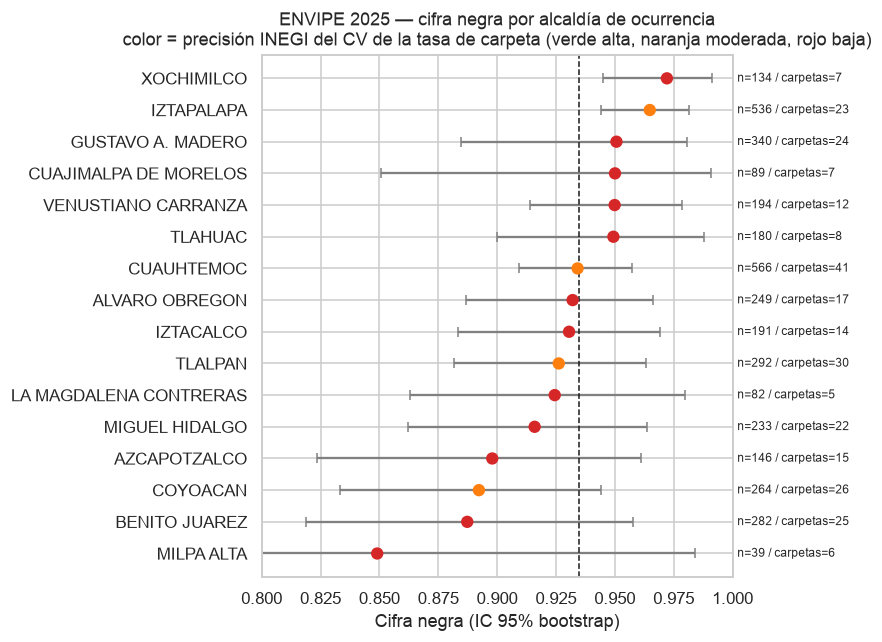

In [5]:
t = tab_alc.drop(["CDMX (total)", "NO ESPECIFICADO"]).sort_values("cifra_negra")
fig, ax = plt.subplots(figsize=(8, 6))
col = t.precision_INEGI.map({"alta": "tab:green", "moderada": "tab:orange", "baja": "tab:red"})
ax.errorbar(t.cifra_negra, t.index, xerr=[t.cifra_negra - t.ic95_inf, t.ic95_sup - t.cifra_negra], fmt="none", ecolor="grey", capsize=3)
ax.scatter(t.cifra_negra, t.index, c=col, s=50, zorder=3)
for y, (_, r) in enumerate(t.iterrows()):
    ax.text(1.002, y, f"n={int(r.n_delitos)} / carpetas={int(r.n_con_carpeta)}", va="center", fontsize=8)
ax.axvline(tab_alc.loc["CDMX (total)", "cifra_negra"], ls="--", c="k", lw=1)
ax.set_xlim(0.80, 1.0); ax.set_xlabel("Cifra negra (IC 95% bootstrap)")
ax.set_title("ENVIPE 2025 — cifra negra por alcaldía de ocurrencia\ncolor = precisión INEGI del CV de la tasa de carpeta (verde alta, naranja moderada, rojo baja)")
plt.tight_layout(); plt.show()

In [6]:
# ¿Hay evidencia de heterogeneidad entre alcaldías? Prueba chi-cuadrada con corrección aproximada por efecto de diseño
t = tab_alc.drop(["CDMX (total)", "NO ESPECIFICADO"])
ct = pd.crosstab(cdmx.alcaldia, cdmx.carpeta).drop("NO ESPECIFICADO")
chi2, p, dof, _ = stats.chi2_contingency(ct)
# deff aprox: varianza bootstrap vs varianza binomial simple del total CDMX
p0 = tab_alc.loc["CDMX (total)", "tasa_carpeta"]; n0 = len(cdmx)
var_boot = (tab_alc.loc["CDMX (total)", "cv_tasa_carpeta"] * p0) ** 2
deff = var_boot / (p0 * (1 - p0) / n0)
print(f"Chi2 ingenuo = {chi2:.1f}, gl = {dof}, p = {p:.4f}")
print(f"Efecto de diseño aprox. (total CDMX) = {deff:.2f} → Chi2 ajustado = {chi2/deff:.1f}, p = {stats.chi2.sf(chi2/deff, dof):.4f}")
print(f"Rango de cifra negra entre alcaldías: {t.cifra_negra.min():.1%} – {t.cifra_negra.max():.1%}")
print(f"Alcaldías con precisión baja (CV>30%): {(t.precision_INEGI=='baja').sum()} de 16")
# Número efectivo de 'eventos' por alcaldía para una regresión en segunda etapa
print(f"Mediana de delitos con carpeta por alcaldía: {t.n_con_carpeta.median():.0f}")

Chi2 ingenuo = 25.2, gl = 15, p = 0.0475
Efecto de diseño aprox. (total CDMX) = 2.61 → Chi2 ajustado = 9.6, p = 0.8419
Rango de cifra negra entre alcaldías: 84.9% – 97.2%
Alcaldías con precisión baja (CV>30%): 12 de 16
Mediana de delitos con carpeta por alcaldía: 16


**Lectura (ENVIPE por alcaldía):**
- La cifra negra CDMX se replica (93.5% vs 93.2% publicado; la diferencia es de definición/redondeo y está dentro del IC 92.3–94.7%).
- Pero la muestra que **sí** tiene carpeta es de solo **288 delitos**: mediana de **16 por alcaldía** (Magdalena Contreras 5, Milpa Alta 6, Xochimilco 7).
- **12 de 16 alcaldías** tienen CV > 30% en la tasa de carpeta (precisión baja según INEGI). Ancho mediano del IC 95%: **~9 puntos porcentuales**.
- El rango aparente (84.9% Milpa Alta – 97.2% Xochimilco) **no es estadísticamente distinguible**: la chi-cuadrada ingenua da p = 0.048, pero al corregir por el efecto de diseño (≈2.6) **p = 0.84**.
- **Implicación para el encuadre:** con ENVIPE 2025 sola, la variable dependiente ("subregistro por alcaldía") es mayoritariamente ruido muestral. El objetivo específico 1 se responde con un **"no, no permite desagregación confiable"**.

### 2.2 ¿Qué más ofrece ENVIPE para la hipótesis? (razones de no denuncia, tipo de delito, sexo)

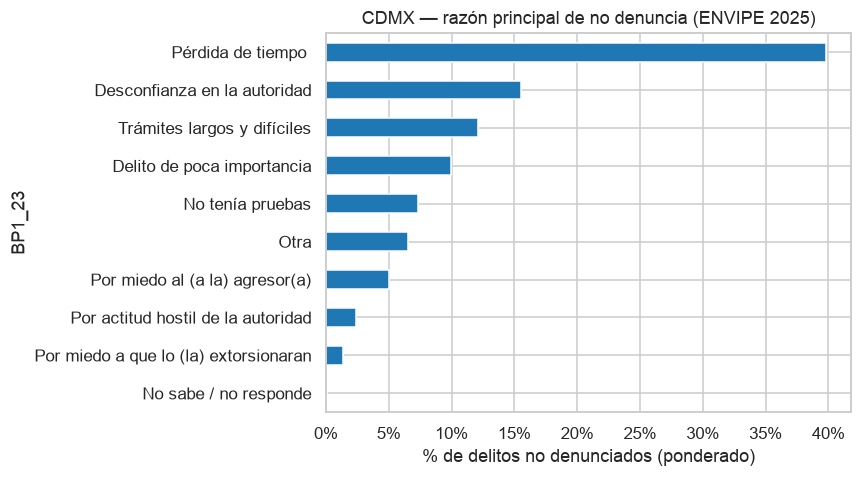

% no denunciado por causas atribuibles a la autoridad: 71.1%


In [7]:
razon = catalogo("tmod_vic", "BP1_23")
nd = cdmx[cdmx.denuncia == 0]
rz = (nd.groupby(nd.BP1_23.map(razon))["FAC_DEL"].sum() / nd.FAC_DEL.sum()).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
rz.plot.barh(ax=ax, color="tab:blue"); ax.set_xlabel("% de delitos no denunciados (ponderado)")
ax.set_title("CDMX — razón principal de no denuncia (ENVIPE 2025)"); ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.tight_layout(); plt.show()

# Causas atribuibles a la autoridad (clasificación INEGI): pérdida de tiempo, trámites, desconfianza, actitud hostil, miedo a extorsión
aut = ["Pérdida de tiempo", "Trámites largos y difíciles", "Desconfianza en la autoridad", "Por actitud hostil de la autoridad", "Por miedo a que lo (la) extorsionaran"]
print(f"% no denunciado por causas atribuibles a la autoridad: {rz[[r for r in rz.index if r.strip() in aut]].sum():.1%}")

In [8]:
delito_cat = catalogo("tmod_vic", "BPCOD")
g = cdmx.groupby("BPCOD").apply(lambda d: pd.Series({"n": len(d), "carpetas": d.carpeta.sum(),
      "cifra_negra": 1 - np.average(d.carpeta, weights=d.FAC_DEL), "peso": d.FAC_DEL.sum()}))
g["delito"] = g.index.map(lambda c: delito_cat.get(c, c)[:70])
g["%_delitos"] = g.peso / g.peso.sum()
display(g.sort_values("peso", ascending=False)[["delito", "n", "carpetas", "%_delitos", "cifra_negra"]])

sx = cdmx.groupby("SEXO").apply(lambda d: pd.Series({"n": len(d), "cifra_negra": 1 - np.average(d.carpeta, weights=d.FAC_DEL)}))
sx.index = sx.index.map({"1": "Hombre", "2": "Mujer"}); sx

,delito,n,carpetas,%_delitos,cifra_negra
BPCOD,,,,,
05,Robo o asalto en la calle o en el transporte p...,562.000,31.000,0.200,0.948
10,Amenazas verbales o por escrito hacia su perso...,330.000,39.000,0.120,0.890
13,Alguien en contra de su voluntad lo (la) agred...,226.000,1.000,0.113,0.995
02,"Robo de accesorios, refacciones o herramientas...",830.000,49.000,0.106,0.935
07,"Alguien usó su chequera, número de tarjeta o c...",369.000,17.000,0.103,0.960
09,"Amenazas, presiones o engaños para exigirle di...",336.000,19.000,0.102,0.941
08,Entregó dinero por un producto o un servicio q...,266.000,7.000,0.080,0.977
03,"Pinta de barda o grafiti en su casa, rayones i...",505.000,10.000,0.063,0.979
11,Alguien solo por actitud abusiva o por una dis...,149.000,28.000,0.047,0.843


,n,cifra_negra
SEXO,,
Hombre,"1,883.000",0.936
Mujer,"2,024.000",0.933


**Lectura:** la cifra negra varía mucho más **por tipo de delito** (robo total de vehículo 36% vs acoso sexual 99.5%) que por alcaldía. Como la mezcla de delitos cambia entre alcaldías, parte de cualquier diferencia territorial sería **composición**, no propensión a denunciar. Por sexo no hay diferencia agregada (93.6% H vs 93.3% M), lo que debilita la extensión 5 tal como está planteada (habría que cruzar sexo × tipo de delito).

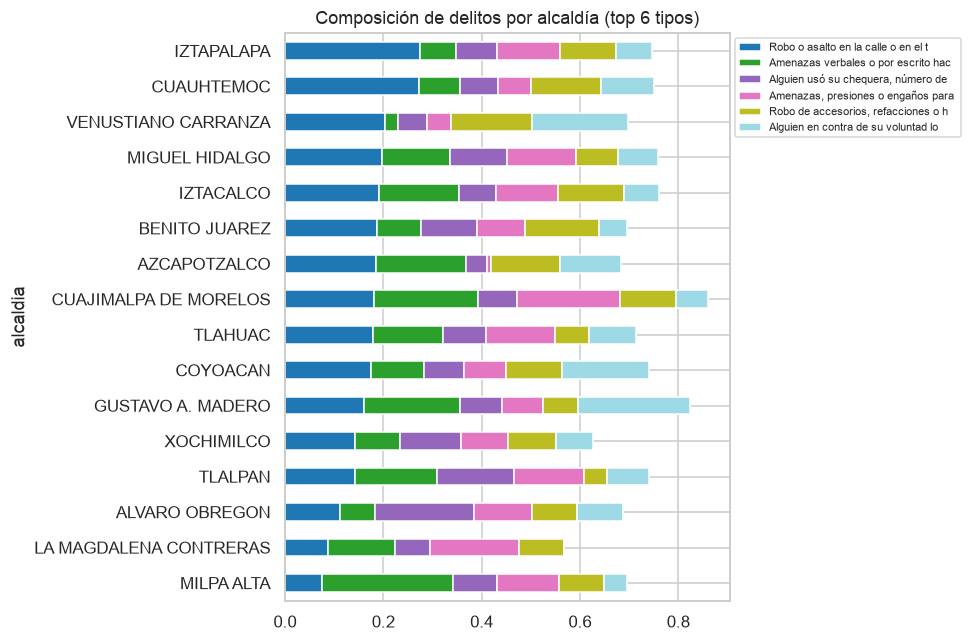

In [9]:
# Mezcla de delitos por alcaldía: ¿la variación en cifra negra es composición del tipo de delito?
mix = pd.crosstab(cdmx.alcaldia, cdmx.BPCOD.map(lambda c: delito_cat.get(c, c)[:35]), values=cdmx.FAC_DEL, aggfunc="sum", normalize="index")
top = mix.mean().sort_values(ascending=False).index[:6]
mix[top].drop("NO ESPECIFICADO").sort_values(top[0]).plot.barh(stacked=True, figsize=(9, 6), colormap="tab20")
plt.legend(bbox_to_anchor=(1, 1), fontsize=7); plt.title("Composición de delitos por alcaldía (top 6 tipos)"); plt.tight_layout(); plt.show()

## 3. Carpetas de investigación FGJ

In [10]:
fgj = pd.read_csv(ROOT / "carpetas-datos/carpetasFGJ_acumulado_2025_01.csv", engine="pyarrow",
                  usecols=["anio_inicio", "fecha_inicio", "fecha_hecho", "delito", "categoria_delito",
                           "colonia_hecho", "colonia_catalogo", "alcaldia_hecho", "latitud", "longitud"])
fgj["fecha_hecho"] = pd.to_datetime(fgj.fecha_hecho, errors="coerce")
fgj["fecha_inicio"] = pd.to_datetime(fgj.fecha_inicio, errors="coerce")
fgj["alcaldia"] = fgj.alcaldia_hecho.map(norm_alc)
print(fgj.shape)
calidad = pd.DataFrame({
    "% nulos": fgj.isna().mean(),
    "n únicos": fgj.nunique(),
})
display(calidad)
print("Alcaldía 'CDMX (indeterminada)':", (fgj.alcaldia_hecho == "CDMX (indeterminada)").mean().round(4))
print("Hechos fuera de CDMX / otros valores:", sorted(set(fgj.alcaldia.dropna()) - set(t.index)))
lag = (fgj.fecha_inicio - fgj.fecha_hecho).dt.days
print("Rezago hecho→denuncia (días): mediana", lag.median(), "| p90", lag.quantile(.9), "| % > 365 días", (lag > 365).mean().round(4))

(2098743, 11)


,% nulos,n únicos
anio_inicio,0.000,10
fecha_inicio,0.000,56539
fecha_hecho,0.000,32261
delito,0.000,357
categoria_delito,0.000,18
colonia_hecho,0.049,1699
colonia_catalogo,0.059,1423
alcaldia_hecho,0.012,17
latitud,0.048,846185
longitud,0.048,836872


Alcaldía 'CDMX (indeterminada)': 0.0084


Hechos fuera de CDMX / otros valores: ['CDMX (INDETERMINADA)']
Rezago hecho→denuncia (días): mediana 1.0 | p90 71.0 | % > 365 días 0.0326


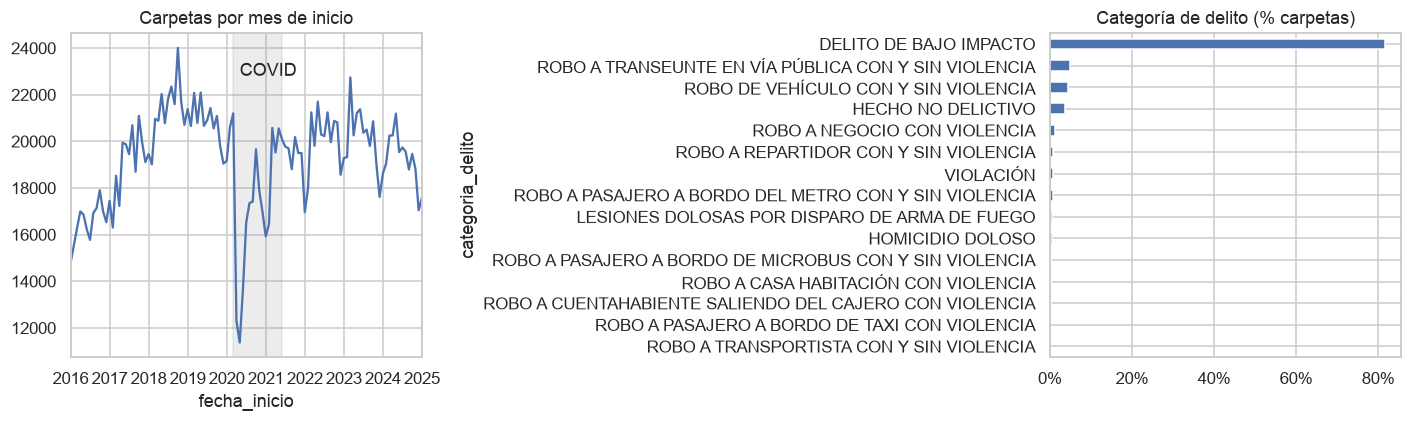

Número de 'delito' distintos: 357 | categorías: 18


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
m = fgj.set_index("fecha_inicio").resample("MS").size()
m.plot(ax=axes[0]); axes[0].set_title("Carpetas por mes de inicio"); axes[0].axvspan("2020-03", "2021-06", alpha=.15, color="grey")
axes[0].annotate("COVID", ("2020-05", m.max() * .95))
(fgj.categoria_delito.value_counts(normalize=True).head(15)[::-1]).plot.barh(ax=axes[1])
axes[1].set_title("Categoría de delito (% carpetas)"); axes[1].xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plt.tight_layout(); plt.show()
print("Número de 'delito' distintos:", fgj.delito.nunique(), "| categorías:", fgj.categoria_delito.nunique())

**Lectura (FGJ):** 2.1 M carpetas, 357 delitos en 18 categorías, 4.8% sin coordenadas, 1.2% sin alcaldía (0.8% "indeterminada"). 2025 solo trae enero (corte del acumulado). El rezago hecho→inicio tiene mediana de 1 día, pero p90 de 71 días: los últimos meses de 2024 pueden estar sub-contados. Quiebre claro por COVID (2020–2021).

### 3.1 Población por alcaldía (Censo 2020 AGEB) y tasas FGJ 2024 (año de referencia de ENVIPE 2025)

In [12]:
tmp = Path("/tmp/ageb_censo2020"); tmp.mkdir(exist_ok=True)
with zipfile.ZipFile(next((ROOT / "AGEB").glob("*.zip"))) as z:
    z.extractall(tmp)
ageb = gpd.read_file(tmp / "total.shp")
ageb["alcaldia"] = ageb.alc.map(norm_alc)
dic_ageb = pd.read_excel(next((ROOT / "AGEB").glob("*.xlsx")))
print(ageb.shape, ageb.crs, "| población total:", f"{ageb.pob.sum():,.0f}")
display(dic_ageb[["Nombre", "Etiqueta"]])
pob = ageb.groupby("alcaldia").pob.sum()

f24 = fgj[fgj.fecha_hecho.dt.year == 2024]
alc = pd.DataFrame({"carpetas_2024": f24.groupby("alcaldia").size(), "pob": pob}).dropna()
alc["tasa_100k"] = alc.carpetas_2024 / alc.pob * 1e5
alc = alc.join(tab_alc[["delitos_expandidos", "cifra_negra", "ic95_inf", "ic95_sup", "cv_tasa_carpeta", "n_delitos"]])
alc["envipe_por_carpeta"] = alc.delitos_expandidos / alc.carpetas_2024
alc["ajuste_ingenuo_100k"] = alc.tasa_100k / (1 - alc.cifra_negra)
alc["ajuste_inf"] = alc.tasa_100k / (1 - alc.ic95_inf)
alc["ajuste_sup"] = alc.tasa_100k / (1 - alc.ic95_sup)
alc.sort_values("tasa_100k", ascending=False)

(2433, 35) EPSG:4326 | población total: 9,145,632


,Nombre,Etiqueta
0,alc,Alcaldía
1,loc,Localidad
2,amb_loc,Tipo de localidad
3,ageb,Clave AGEB
4,pob,Población
5,p_3ymas,Población 3 años y más
6,p_12ymas,Población 12 años y más
7,p_nacoe,Población nacida en otra entidad
8,p_vivoe,Población que vivía en otra entidad
9,p_hli,Población que habla lengua indígena


,carpetas_2024,pob,tasa_100k,delitos_expandidos,cifra_negra,ic95_inf,ic95_sup,cv_tasa_carpeta,n_delitos,envipe_por_carpeta,ajuste_ingenuo_100k,ajuste_inf,ajuste_sup
alcaldia,,,,,,,,,,,,,
CUAUHTEMOC,29703,"545,884.000","5,441.266","652,161.000",0.934,0.910,0.957,0.188,566.000,21.956,"82,671.266","60,124.720","127,700.228"
BENITO JUAREZ,15740,"434,153.000","3,625.450","266,051.000",0.887,0.819,0.958,0.323,282.000,16.903,"32,172.196","20,011.751","85,427.334"
MIGUEL HIDALGO,12386,"414,470.000","2,988.395","216,640.000",0.916,0.862,0.964,0.314,233.000,17.491,"35,548.312","21,694.892","82,296.847"
VENUSTIANO CARRANZA,12084,"443,704.000","2,723.437","212,499.000",0.950,0.914,0.978,0.348,194.000,17.585,"54,371.260","31,709.510","125,774.771"
IZTACALCO,9865,"404,695.000","2,437.638","211,012.000",0.931,0.884,0.969,0.322,191.000,21.390,"35,101.059","20,939.992","79,503.554"
COYOACAN,14936,"614,447.000","2,430.804","298,436.000",0.892,0.833,0.944,0.263,264.000,19.981,"22,564.209","14,570.305","43,565.192"
AZCAPOTZALCO,8999,"432,205.000","2,082.114","136,665.000",0.898,0.824,0.961,0.360,146.000,15.187,"20,399.461","11,797.204","53,626.484"
TLALPAN,14067,"681,501.000","2,064.120","368,084.000",0.926,0.882,0.963,0.292,292.000,26.166,"27,958.404","17,446.542","56,324.699"
MILPA ALTA,2353,"128,710.000","1,828.141","54,890.000",0.849,0.730,0.984,0.453,39.000,23.328,"12,111.846","6,779.547","115,283.925"


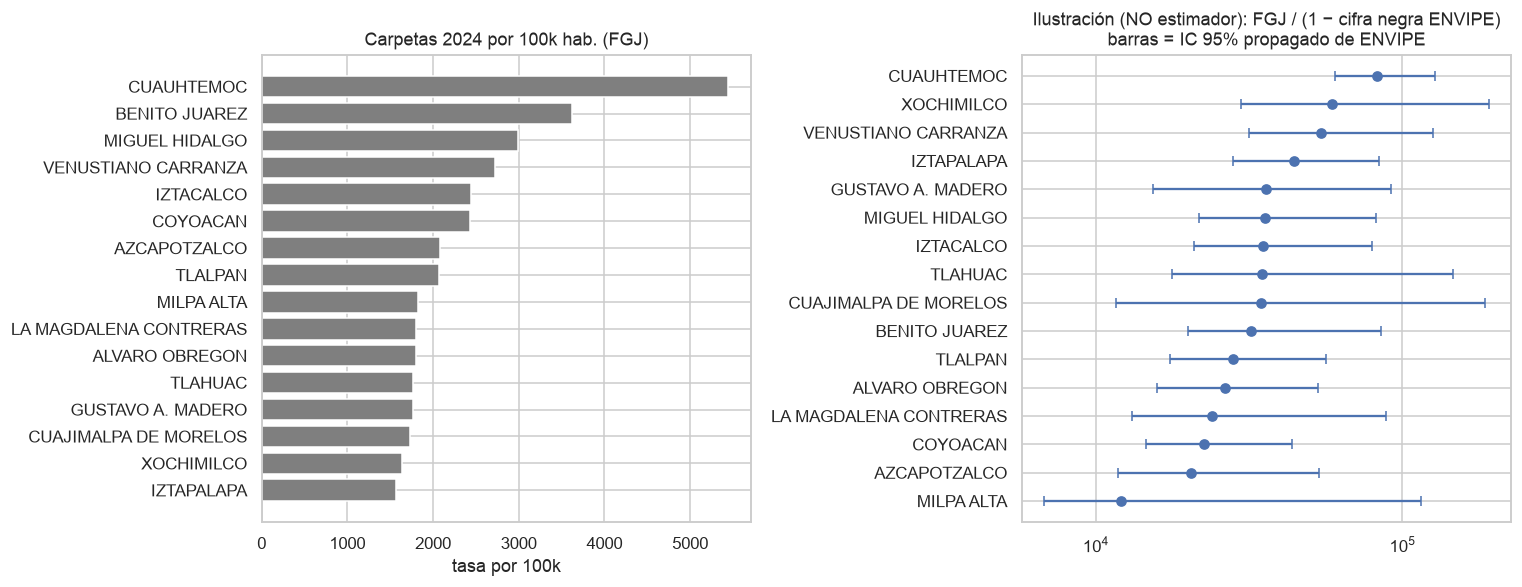

Correlación Spearman tasa FGJ vs cifra negra ENVIPE: SignificanceResult(statistic=np.float64(-0.6088235294117647), pvalue=np.float64(0.012315203198246461))
Razón delitos ENVIPE expandidos / carpetas FGJ 2024 (por alcaldía):
count   16.000
mean    21.754
std      5.595
min     14.386
25%     17.562
50%     21.126
75%     24.037
max     34.697
Name: envipe_por_carpeta, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
a = alc.sort_values("tasa_100k")
axes[0].barh(a.index, a.tasa_100k, color="tab:grey", label="FGJ registrada")
axes[0].set_title("Carpetas 2024 por 100k hab. (FGJ)"); axes[0].set_xlabel("tasa por 100k")
a2 = alc.sort_values("ajuste_ingenuo_100k")
axes[1].errorbar(a2.ajuste_ingenuo_100k, a2.index, xerr=[a2.ajuste_ingenuo_100k - a2.ajuste_inf, a2.ajuste_sup - a2.ajuste_ingenuo_100k], fmt="o", capsize=3)
axes[1].set_xscale("log"); axes[1].set_title("Ilustración (NO estimador): FGJ / (1 − cifra negra ENVIPE)\nbarras = IC 95% propagado de ENVIPE")
plt.tight_layout(); plt.show()
print("Correlación Spearman tasa FGJ vs cifra negra ENVIPE:", stats.spearmanr(alc.tasa_100k, alc.cifra_negra))
print("Razón delitos ENVIPE expandidos / carpetas FGJ 2024 (por alcaldía):"); print(alc.envipe_por_carpeta.describe())

**Lectura:** la razón "delitos ENVIPE expandidos / carpetas FGJ" va de 14× a 35× (mediana 21×). Aplicar el factor por alcaldía produce intervalos que abarcan casi un orden de magnitud en alcaldías pequeñas (Cuajimalpa, Milpa Alta), por lo que un "estimador ajustado" heredaría esa incertidumbre.

Hay un patrón interesante (ρ = −0.61, p = 0.012): **donde la FGJ registra más carpetas per cápita (Cuauhtémoc, Benito Juárez, Miguel Hidalgo), la cifra negra ENVIPE tiende a ser menor**. Es coherente con que la tasa registrada refleje, en parte, facilidad de denunciar y población flotante, no solo incidencia; justo el fenómeno que motiva el caso.

> **Advertencia de comparabilidad:** ENVIPE mide delitos contra personas ≥18 años y hogares (excluye homicidio, narcomenudeo, delitos contra empresas, etc.), y la alcaldía es la de **ocurrencia declarada** por la víctima; FGJ cuenta carpetas (una carpeta puede tener varios delitos/víctimas) y `alcaldia_hecho` es la registrada por la fiscalía. La razón ENVIPE/FGJ mezcla universo distinto con subregistro.

## 4. Covariables del Censo 2020 a nivel AGEB

In [14]:
covs = [c for c in ageb.columns if c.startswith("t_")]
print("Covariables porcentuales disponibles:", covs)
hipotesis = pd.DataFrame({
    "variable de la hipótesis": ["Escolaridad (GRAPROES)", "Hacinamiento (PRO_OCUP_C / VPH_1CUART)", "Proxy confianza institucional", "Derechohabiencia / ingreso proxy"],
    "¿en el shapefile descargado?": ["No", "No", "No (no existe en Censo)", "No"],
    "dónde conseguirla": ["Censo 2020 ITER/RESAGEBURB (INEGI)", "Censo 2020 RESAGEBURB", "ENVIPE AP5 / ENSU BP1_8 (alcaldía, no AGEB)", "RESAGEBURB; IMM CONAPO 2020 por AGEB"],
})
display(hipotesis)
display(ageb[covs + ["pob"]].describe().T)

Covariables porcentuales disponibles: ['t_nacoe', 't_vivoe', 't_hli', 't_hl_nh', 't_hli_h', 't_afrmx', 't_p12ym_sl', 't_p12ym_c', 't_p12ym_sp', 't_catlc', 't_criev', 't_trsrl', 't_sinrl']


,variable de la hipótesis,¿en el shapefile descargado?,dónde conseguirla
0,Escolaridad (GRAPROES),No,Censo 2020 ITER/RESAGEBURB (INEGI)
1,Hacinamiento (PRO_OCUP_C / VPH_1CUART),No,Censo 2020 RESAGEBURB
2,Proxy confianza institucional,No (no existe en Censo),"ENVIPE AP5 / ENSU BP1_8 (alcaldía, no AGEB)"
3,Derechohabiencia / ingreso proxy,No,RESAGEBURB; IMM CONAPO 2020 por AGEB


,count,mean,std,min,25%,50%,75%,max
t_nacoe,"2,405.000",18.503,6.284,0.000,14.761,17.647,21.149,85.455
t_vivoe,"2,390.000",3.588,3.392,0.000,1.873,2.820,4.439,84.941
t_hli,"2,350.000",1.476,3.192,0.000,0.650,0.987,1.621,96.124
t_hl_nh,"1,961.000",0.005,0.025,0.000,0.000,0.000,0.000,0.328
t_hli_h,"2,350.000",1.453,3.164,0.000,0.639,0.975,1.601,94.574
t_afrmx,"2,365.000",2.063,2.420,0.000,0.901,1.506,2.511,38.660
t_p12ym_sl,"2,405.000",38.244,3.871,0.000,36.123,38.112,40.151,92.047
t_p12ym_c,"2,405.000",46.652,4.622,0.000,43.676,46.442,49.579,84.848
t_p12ym_sp,"2,401.000",14.947,2.870,0.000,13.388,14.875,16.429,57.143
t_catlc,"2,406.000",75.576,6.376,0.000,72.705,76.218,79.354,100.000


**Hallazgo crítico:** el shapefile AGEB descargado es el de **características demográficas** (migración, lengua indígena, afromexicanos, situación conyugal, religión). **No contiene ninguna de las variables de la hipótesis** (escolaridad, hacinamiento). Hay que descargar los *Principales resultados por AGEB y manzana urbana* (RESAGEBURB) del Censo 2020 para CDMX; se une por `CVEGEO` de AGEB sin fricción. "Confianza institucional" no existe en el Censo: solo se puede medir en ENVIPE/ENSU a nivel alcaldía.

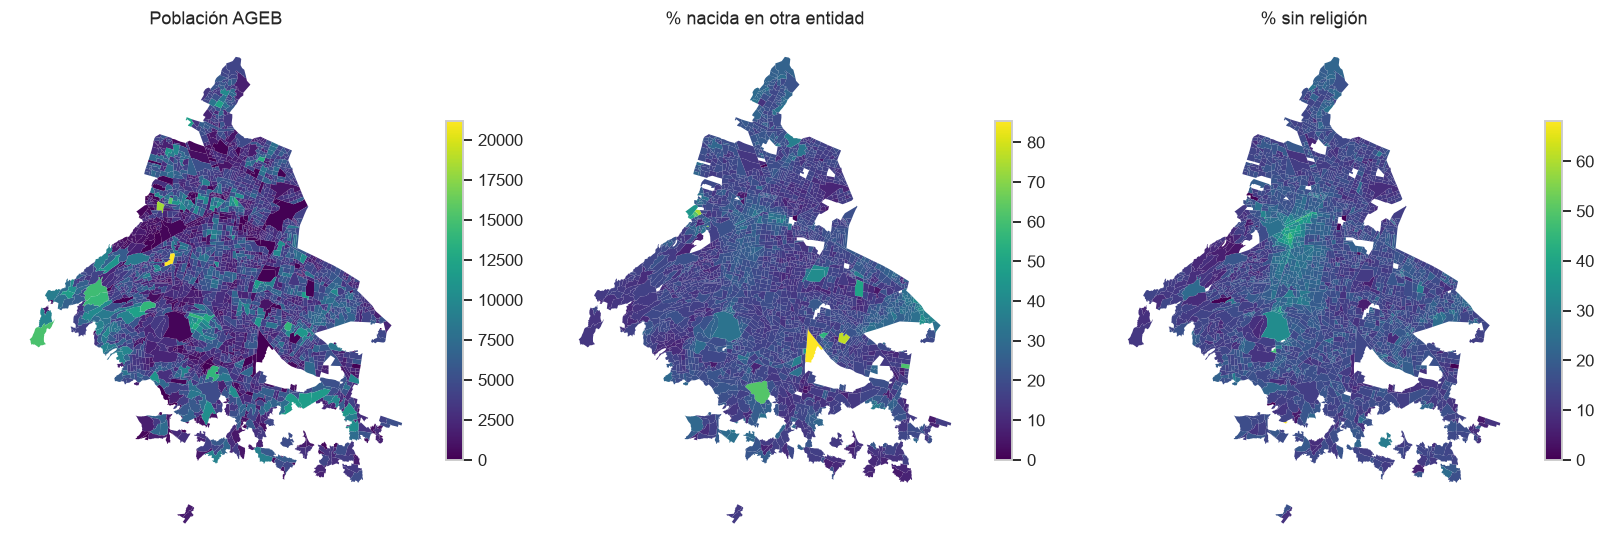

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, c, ttl in zip(axes, ["pob", "t_nacoe", "t_sinrl"], ["Población AGEB", "% nacida en otra entidad", "% sin religión"]):
    ageb.plot(column=c, ax=ax, cmap="viridis", legend=True, scheme=None, linewidth=0, legend_kwds={"shrink": .6})
    ax.set_title(ttl); ax.set_axis_off()
plt.tight_layout(); plt.show()

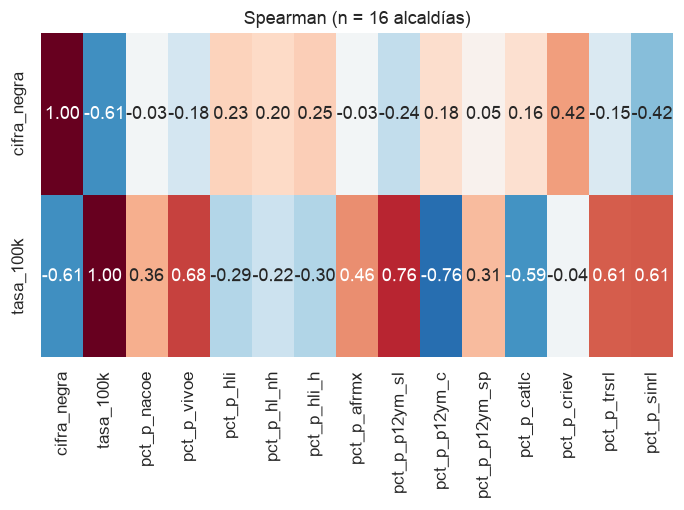

Con n=16, |rho| necesario para p<0.05: 0.50


In [16]:
# Agregado a alcaldía: con n = 16 cualquier correlación es muy inestable
alc_cov = ageb.assign(**{c.replace("t_", "p_"): ageb[c] * ageb.pob / 100 for c in covs}).groupby("alcaldia")[[c.replace("t_", "p_") for c in covs] + ["pob"]].sum()
alc_cov = alc_cov.div(alc_cov.pob, axis=0).drop(columns="pob").add_prefix("pct_")
alc2 = alc.join(alc_cov)
cor = alc2[["cifra_negra", "tasa_100k"] + list(alc_cov.columns)].corr(method="spearman")
sns.heatmap(cor.iloc[:2], annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("Spearman (n = 16 alcaldías)"); plt.tight_layout(); plt.show()
n = 16
print(f"Con n={n}, |rho| necesario para p<0.05: {stats.t.ppf(.975, n-2) / np.sqrt(n - 2 + stats.t.ppf(.975, n-2)**2):.2f}")

**Lectura:** con 16 alcaldías se necesita |ρ| ≥ 0.50 solo para p < 0.05 y no hay grados de libertad para más de 1–2 covariables. Cualquier "factor sociodemográfico que explica la variación" a nivel alcaldía sería frágil y difícil de defender ante sinodales.

## 5. ENSU 2026 (T1 + T2) — percepción y confianza, representativa por alcaldía

In [17]:
def read_ensu(zpath):
    z = zipfile.ZipFile(zpath)
    name = [n for n in z.namelist() if re.search(r"ensu_cb_\d+\.csv$", n)][0]
    d = pd.read_csv(io.BytesIO(z.read(name)), dtype=str)
    d["trimestre"] = re.search(r"cb_(\d+)", name).group(1)
    return d

ensu = pd.concat([read_ensu(p) for p in sorted((ROOT / "ENSU").glob("*.zip"))])
ensu = ensu[ensu.CVE_ENT == "09"].copy()
ensu["FAC_SEL"] = ensu.FAC_SEL.astype(float)
ensu["alcaldia"] = ensu.NOM_CD.map(norm_alc)
print(ensu.groupby(["trimestre"]).size(), ensu.groupby("alcaldia").size().describe(), sep="\n")

def wprop(d, var, val):
    ok = d[var].isin(["1", "2", "3", "4"]) if var != "BP1_1" else d[var].isin(["1", "2"])
    d = d[ok]
    return np.average(d[var].isin(val), weights=d.FAC_SEL)

ens_alc = ensu.groupby("alcaldia").apply(lambda d: pd.Series({
    "n_ensu": len(d),
    "pct_inseguro_ciudad": wprop(d, "BP1_1", ["2"]),
    "pct_policia_SSC_poco_nada_efectiva": wprop(d, "BP1_8_2", ["3", "4"]),
    "pct_gobierno_poco_nada_efectivo": wprop(d, "BP3_2", ["3", "4"]),
}))
alc3 = alc2.join(ens_alc)
alc3[["n_ensu", "pct_inseguro_ciudad", "pct_policia_SSC_poco_nada_efectiva", "pct_gobierno_poco_nada_efectivo", "tasa_100k", "cifra_negra"]].sort_values("pct_inseguro_ciudad")

trimestre
0326    4259
0626    4216
dtype: int64
count    16.000
mean    529.688
std      10.183
min     516.000
25%     522.000
50%     526.500
75%     536.500
max     548.000
dtype: float64


,n_ensu,pct_inseguro_ciudad,pct_policia_SSC_poco_nada_efectiva,pct_gobierno_poco_nada_efectivo,tasa_100k,cifra_negra
alcaldia,,,,,,
BENITO JUAREZ,524.000,0.169,0.405,0.603,"3,625.450",0.887
MIGUEL HIDALGO,520.000,0.378,0.384,0.549,"2,988.395",0.916
COYOACAN,523.000,0.439,0.568,0.639,"2,430.804",0.892
CUAJIMALPA DE MORELOS,532.000,0.502,0.471,0.711,"1,730.322",0.950
MILPA ALTA,548.000,0.509,0.507,0.722,"1,828.141",0.849
CUAUHTEMOC,522.000,0.530,0.503,0.692,"5,441.266",0.934
TLALPAN,522.000,0.539,0.540,0.735,"2,064.120",0.926
VENUSTIANO CARRANZA,529.000,0.565,0.466,0.614,"2,723.437",0.950
LA MAGDALENA CONTRERAS,519.000,0.582,0.572,0.738,"1,803.367",0.924


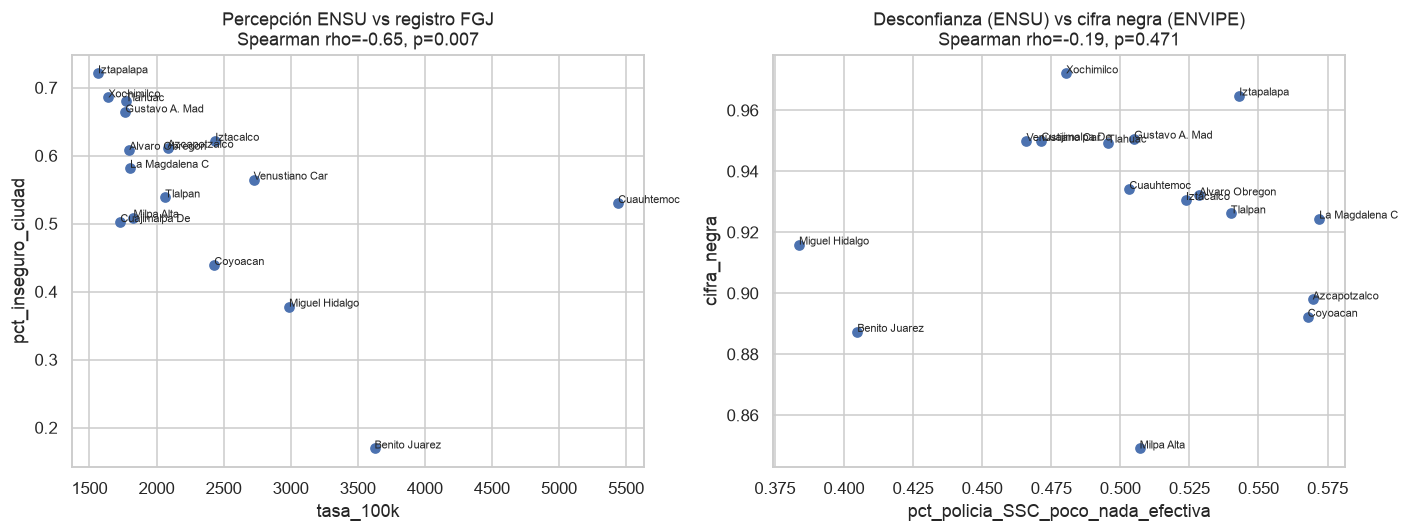

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (x, y, ttl) in zip(axes, [("tasa_100k", "pct_inseguro_ciudad", "Percepción ENSU vs registro FGJ"),
                                    ("pct_policia_SSC_poco_nada_efectiva", "cifra_negra", "Desconfianza (ENSU) vs cifra negra (ENVIPE)")]):
    ax.scatter(alc3[x], alc3[y])
    for i, r in alc3.iterrows():
        ax.annotate(i.title()[:14], (r[x], r[y]), fontsize=7)
    rho, p = stats.spearmanr(alc3[x], alc3[y])
    ax.set_xlabel(x); ax.set_ylabel(y); ax.set_title(f"{ttl}\nSpearman rho={rho:.2f}, p={p:.3f}")
plt.tight_layout(); plt.show()

**Lectura (ENSU):** ENSU sí es representativa por alcaldía (~530 entrevistas por alcaldía en 2 trimestres, diseño balanceado) — mucho mejor grano que ENVIPE para actitudes. Hallazgos:
- **Paradoja percepción–registro:** la percepción de inseguridad es *inversa* a la tasa FGJ (ρ = −0.65). Benito Juárez: 17% se siente insegura, pero es la 2ª tasa FGJ más alta; Iztapalapa: 72% insegura y la tasa FGJ más baja.
- La percepción sí va en la misma dirección que la cifra negra ENVIPE (ρ = +0.67).
- La (des)confianza en la policía (SSC) **no** se asocia con la cifra negra por alcaldía (ρ = −0.19, p = 0.47). La variable "policía municipal" no aplica en CDMX (todas las respuestas son "no aplica"); se usó Policía Estatal (SSC).
- Nota: ENSU es 2026 y ENVIPE refiere a 2024; la comparación es de gradientes territoriales, no del mismo periodo.

## 6. Llamadas 911 (C5) — proxy alternativo de incidencia no denunciada

In [19]:
c5 = pd.read_csv(ROOT / "911_llamadas_datos/llamadas_911_2022_s1.csv", engine="pyarrow")
c5["fecha_creacion"] = pd.to_datetime(c5.fecha_creacion, errors="coerce")
print("Rango de fechas:", c5.fecha_creacion.min(), "→", c5.fecha_creacion.max())
print(c5.fecha_creacion.dt.to_period("M").value_counts().sort_index().tail(8))
display(c5.clas_con_f_alarma.value_counts(normalize=True))
display(c5[c5.clas_con_f_alarma == "DELITO"].groupby(["categoria_incidente_c4", "incidente_c4"]).size().sort_values(ascending=False).head(15))
print("% nulos:"); print(c5.isna().mean().round(3))

Rango de fechas: 2020-03-07 00:00:00 → 2022-04-30 00:00:00
fecha_creacion
2021-02         2
2021-03         5
2021-08         1
2021-12      1038
2022-01     88721
2022-02     86512
2022-03    104274
2022-04    109474
Freq: M, Name: count, dtype: int64


clas_con_f_alarma
SERVICIO            0.291
DELITO              0.238
FALTA CÍVICA        0.218
URGENCIAS MEDICAS   0.165
EMERGENCIA          0.088
FALSA ALARMA        0.000
Name: proportion, dtype: float64

categoria_incidente_c4  incidente_c4        
Agresion                Persona                 46523
                        Casa habitacion          9060
Disturbio               Disparos                 8003
                        Rina                     7813
Danos                   Propiedad ajena          3378
Disturbio               Quema de pirotecnia      2987
Agresion                Negocio                  1787
Denuncia                Menor en riesgo          1698
Robo                    Otros                    1217
Amenaza                 A persona                1145
Robo                    Automovilista            1128
Lesionado               Por arma blanca          1116
Denuncia                Extorsion telefonica     1094
                        Maltrato animal          1083
Detencion ciudadana     Robo                      885
dtype: int64

% nulos:
folio                    0.000
categoria_incidente_c4   0.000
incidente_c4             0.000
anio_creacion            0.000
mes_creacion             0.000
fecha_creacion           0.000
hora_creacion            0.000
anio_cierre              0.000
mes_cierre               0.000
fecha_cierre             0.000
hora_cierre              0.000
codigo_cierre            0.000
clas_con_f_alarma        0.000
alcaldia_cierre          0.000
colonia_cierre           0.000
manzana                  0.015
latitud                  0.000
longitud                 0.000
dtype: float64


In [20]:
ini, fin = "2022-01-01", "2022-04-30"
c5d = c5[(c5.clas_con_f_alarma == "DELITO") & c5.fecha_creacion.between(ini, fin)].copy()
c5d["alcaldia"] = c5d.alcaldia_cierre.map(norm_alc)
fgj22 = fgj[fgj.fecha_hecho.between(ini, fin)]
cmp = pd.DataFrame({"llamadas_delito_911": c5d.groupby("alcaldia").size(), "carpetas_fgj": fgj22.groupby("alcaldia").size()}).dropna()
cmp["llamadas_por_carpeta"] = cmp.llamadas_delito_911 / cmp.carpetas_fgj
cmp = cmp.join(alc3[["cifra_negra", "pct_policia_SSC_poco_nada_efectiva"]])
display(cmp.sort_values("llamadas_por_carpeta"))
print("Spearman llamadas/carpeta vs cifra negra ENVIPE:", stats.spearmanr(cmp.llamadas_por_carpeta, cmp.cifra_negra))

,llamadas_delito_911,carpetas_fgj,llamadas_por_carpeta,cifra_negra,pct_policia_SSC_poco_nada_efectiva
alcaldia,,,,,
BENITO JUAREZ,"4,409.000",5442,0.810,0.887,0.405
CUAUHTEMOC,"9,386.000",11446,0.820,0.934,0.503
MIGUEL HIDALGO,"3,969.000",4517,0.879,0.916,0.384
MILPA ALTA,798.000,834,0.957,0.849,0.507
CUAJIMALPA DE MORELOS,"1,210.000",1263,0.958,0.950,0.471
AZCAPOTZALCO,"4,210.000",3801,1.108,0.898,0.570
TLAHUAC,"3,161.000",2621,1.206,0.949,0.496
ALVARO OBREGON,"6,326.000",5243,1.207,0.932,0.529
COYOACAN,"6,550.000",5336,1.228,0.892,0.568


Spearman llamadas/carpeta vs cifra negra ENVIPE: SignificanceResult(statistic=np.float64(0.6058823529411764), pvalue=np.float64(0.012860298533367195))


**Lectura (911 vs FGJ, ene–abr 2022):** la razón *llamadas de delito al 911 por carpeta* va de 0.8 (Benito Juárez, Cuauhtémoc) a 1.7 (Iztapalapa), y **se correlaciona con la cifra negra ENVIPE (ρ = +0.61, p = 0.013)** y con la percepción de inseguridad ENSU (ρ = +0.74). Es decir, **dos fuentes administrativas independientes reproducen el gradiente centro–periferia que ENVIPE sugiere pero no puede estimar con precisión**. Cuidado: 911 y FGJ no son el mismo universo (agresiones y riñas dominan las llamadas; fraudes y robos sin violencia dominan las carpetas), y el archivo solo cubre ene–abr 2022.

### 6.1 ¿Se puede bajar a AGEB? Unión espacial de FGJ 2024 y 911 a polígonos AGEB

In [21]:
def a_ageb(df, lat="latitud", lon="longitud"):
    d = df.dropna(subset=[lat, lon])
    d = d[d[lat].between(19.0, 19.7) & d[lon].between(-99.4, -98.9)]
    g = gpd.GeoDataFrame(d, geometry=gpd.points_from_xy(d[lon], d[lat]), crs="EPSG:4326")
    j = gpd.sjoin(g, ageb[["ageb", "geometry"]], how="left", predicate="within")
    return j

j_fgj = a_ageb(f24)
j_c5 = a_ageb(c5d)
print(f"FGJ 2024: {len(f24):,} carpetas | con coordenadas válidas {len(j_fgj)/len(f24):.1%} | caen en AGEB urbana {j_fgj.ageb.notna().mean():.1%}")
print(f"911 delito ene–abr 2022: {len(c5d):,} | con coordenadas válidas {len(j_c5)/len(c5d):.1%} | caen en AGEB urbana {j_c5.ageb.notna().mean():.1%}")
ag = ageb.set_index("ageb")[["alcaldia", "pob"] + covs].copy()
ag["carpetas_2024"] = j_fgj.groupby("ageb").size()
ag["llamadas_911"] = j_c5.groupby("ageb").size()
ag = ag.fillna({"carpetas_2024": 0, "llamadas_911": 0})
ag["tasa_fgj_1k"] = ag.carpetas_2024 / ag.pob.replace(0, np.nan) * 1e3
print(ag[["carpetas_2024", "llamadas_911", "tasa_fgj_1k"]].describe(percentiles=[.5, .9, .99]))

FGJ 2024: 216,965 carpetas | con coordenadas válidas 93.7% | caen en AGEB urbana 99.7%
911 delito ene–abr 2022: 92,235 | con coordenadas válidas 100.0% | caen en AGEB urbana 99.8%
       carpetas_2024  llamadas_911  tasa_fgj_1k
count      2,433.000     2,433.000    2,416.000
mean          83.343        37.816      101.497
std           76.984        28.397    1,296.115
min            0.000         0.000        0.000
50%           65.000        32.000       17.840
90%          166.000        76.000       52.672
99%          364.480       127.000    1,091.410
max          868.000       239.000   44,857.143


**Lectura:** el 93.5% de las carpetas 2024 y el 99.8% de las llamadas 911 se asignan a un AGEB urbano por coordenadas. **El grano AGEB (~2,400 unidades) es técnicamente viable** y evita la fricción de nombres de colonia (solo 38% de coincidencia exacta entre 911 y FGJ). Ojo con AGEB de poca población residente y mucha actividad (Centro, corredores comerciales): la tasa por residente explota (máx. ~45k por 1k hab.), por lo que se necesita un denominador alternativo o un modelo de conteo con offset.

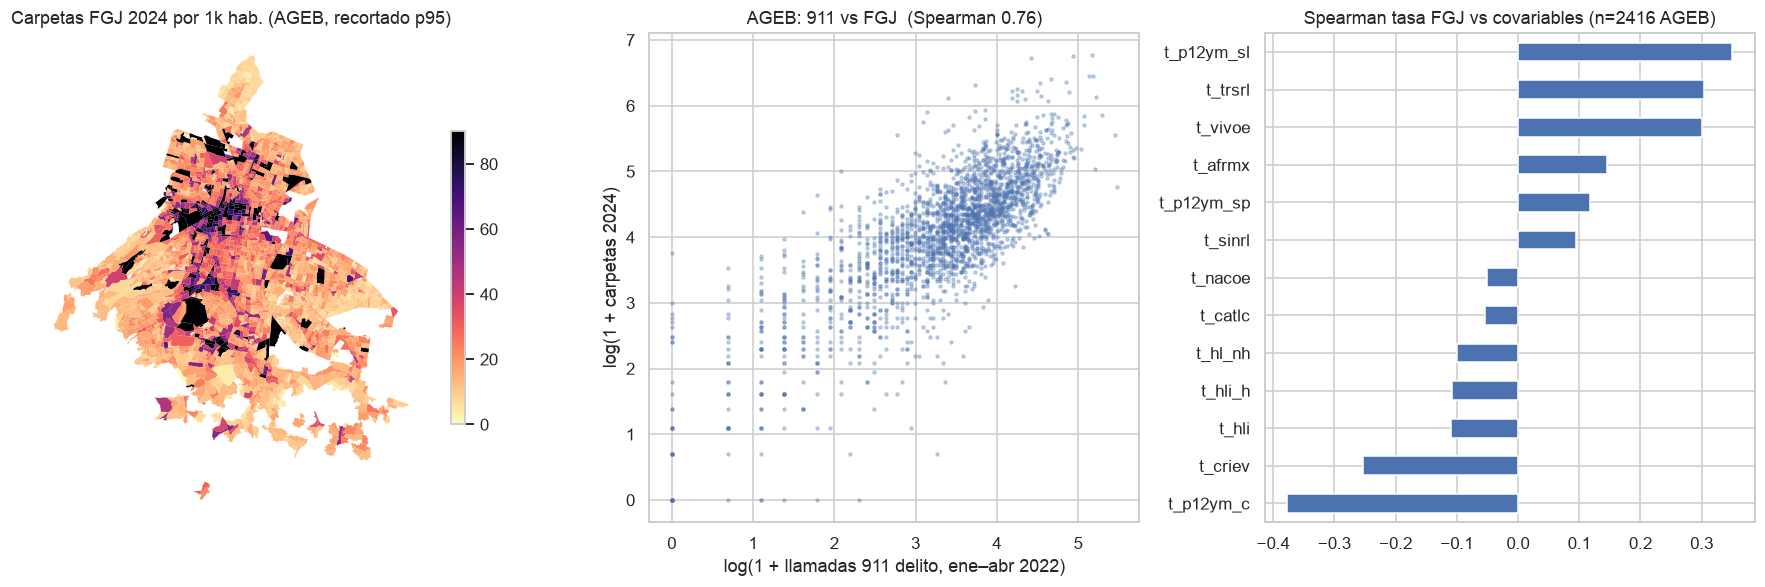

AGEB con población 0 o nula: 17 | Top 1% de AGEB concentra 6.4% de carpetas


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
ageb.merge(ag[["tasa_fgj_1k"]], left_on="ageb", right_index=True).plot(column="tasa_fgj_1k", ax=axes[0], cmap="magma_r", linewidth=0, legend=True, vmax=ag.tasa_fgj_1k.quantile(.95), legend_kwds={"shrink": .6})
axes[0].set_title("Carpetas FGJ 2024 por 1k hab. (AGEB, recortado p95)"); axes[0].set_axis_off()
axes[1].scatter(np.log1p(ag.llamadas_911), np.log1p(ag.carpetas_2024), s=4, alpha=.3)
axes[1].set_xlabel("log(1 + llamadas 911 delito, ene–abr 2022)"); axes[1].set_ylabel("log(1 + carpetas 2024)")
axes[1].set_title(f"AGEB: 911 vs FGJ  (Spearman {stats.spearmanr(ag.llamadas_911, ag.carpetas_2024)[0]:.2f})")
corr_ageb = ag[["tasa_fgj_1k"] + covs].corr(method="spearman")["tasa_fgj_1k"].drop("tasa_fgj_1k").sort_values()
corr_ageb.plot.barh(ax=axes[2]); axes[2].set_title(f"Spearman tasa FGJ vs covariables (n={ag.tasa_fgj_1k.notna().sum()} AGEB)")
plt.tight_layout(); plt.show()
print("AGEB con población 0 o nula:", (ag.pob.fillna(0) == 0).sum(), "| Top 1% de AGEB concentra", f"{ag.carpetas_2024.nlargest(int(len(ag)*.01)).sum()/ag.carpetas_2024.sum():.1%} de carpetas")

## 7. Fricción de joins entre fuentes

In [23]:
sets = {
    "FGJ alcaldia_hecho": set(fgj.alcaldia.dropna()),
    "ENVIPE BP1_3C→NOM_MUN": set(cdmx.alcaldia.dropna()) - {"NO ESPECIFICADO"},
    "Censo AGEB alc": set(ageb.alcaldia),
    "ENSU NOM_CD": set(ensu.alcaldia),
    "911 alcaldia_cierre": set(c5.alcaldia_cierre.dropna().map(norm_alc)),
}
ref = sets["Censo AGEB alc"]
display(pd.DataFrame({k: {"n": len(v), "no_en_Censo": sorted(v - ref)} for k, v in sets.items()}).T)

col_fgj = set(fgj.colonia_hecho.dropna().map(norm))
col_c5 = set(c5.colonia_cierre.dropna().map(norm))
print(f"Colonias únicas FGJ: {len(col_fgj):,} | 911: {len(col_c5):,} | coincidencia exacta normalizada (911 en FGJ): {len(col_c5 & col_fgj)/len(col_c5):.1%}")
print("→ A nivel colonia el join por nombre es frágil; la unión espacial a AGEB (sección 6.1) evita el problema.")

,n,no_en_Censo
FGJ alcaldia_hecho,17,[CDMX (INDETERMINADA)]
ENVIPE BP1_3C→NOM_MUN,16,[]
Censo AGEB alc,17,[]
ENSU NOM_CD,16,[]
911 alcaldia_cierre,16,[]


Colonias únicas FGJ: 1,688 | 911: 1,724 | coincidencia exacta normalizada (911 en FGJ): 38.3%
→ A nivel colonia el join por nombre es frágil; la unión espacial a AGEB (sección 6.1) evita el problema.


In [24]:
# Resumen de correlaciones a nivel alcaldía (n = 16) — todas exploratorias
pares = [("tasa_100k", "cifra_negra"), ("tasa_100k", "pct_inseguro_ciudad"), ("pct_inseguro_ciudad", "cifra_negra"),
         ("pct_policia_SSC_poco_nada_efectiva", "cifra_negra"), ("pct_gobierno_poco_nada_efectivo", "cifra_negra")]
filas = [(x, y, *stats.spearmanr(alc3[x], alc3[y])) for x, y in pares]
filas.append(("llamadas_por_carpeta (911/FGJ)", "cifra_negra", *stats.spearmanr(cmp.llamadas_por_carpeta, cmp.cifra_negra)))
filas.append(("llamadas_por_carpeta (911/FGJ)", "pct_inseguro_ciudad", *stats.spearmanr(cmp.llamadas_por_carpeta, alc3.loc[cmp.index, "pct_inseguro_ciudad"])))
display(pd.DataFrame(filas, columns=["x", "y", "rho_spearman", "p"]))
display(cor.iloc[:2].T.sort_values("cifra_negra"))
print("Valores de alcaldía en Censo AGEB:", ageb.alc.value_counts().to_dict())

,x,y,rho_spearman,p
0,tasa_100k,cifra_negra,-0.609,0.012
1,tasa_100k,pct_inseguro_ciudad,-0.647,0.007
2,pct_inseguro_ciudad,cifra_negra,0.668,0.005
3,pct_policia_SSC_poco_nada_efectiva,cifra_negra,-0.194,0.471
4,pct_gobierno_poco_nada_efectivo,cifra_negra,0.274,0.305
5,llamadas_por_carpeta (911/FGJ),cifra_negra,0.606,0.013
6,llamadas_por_carpeta (911/FGJ),pct_inseguro_ciudad,0.741,0.001


,cifra_negra,tasa_100k
tasa_100k,-0.609,1.000
pct_p_sinrl,-0.421,0.609
pct_p_p12ym_sl,-0.244,0.762
pct_p_vivoe,-0.182,0.676
pct_p_trsrl,-0.150,0.606
pct_p_nacoe,-0.032,0.362
pct_p_afrmx,-0.026,0.465
pct_p_p12ym_sp,0.047,0.312
pct_p_catlc,0.165,-0.594
pct_p_p12ym_c,0.176,-0.765


Valores de alcaldía en Censo AGEB: {'Iztapalapa': 458, 'Gustavo A. Madero': 305, 'Tlalpan': 207, 'Álvaro Obregón': 199, 'Coyoacán': 156, 'Cuauhtémoc': 153, 'Venustiano Carranza': 151, 'Miguel Hidalgo': 130, 'Xochimilco': 122, 'Iztacalco': 110, 'Tláhuac': 110, 'Azcapotzalco': 103, 'Benito Juárez': 102, 'La Magdalena Contreras': 52, 'Milpa Alta': 42, 'Cuajimalpa de Morelos': 31}


## 8. Evaluación del encuadre

In [25]:
t = tab_alc.drop(["CDMX (total)", "NO ESPECIFICADO"])
resumen = {
    "Cifra negra CDMX (replica INEGI)": f"{tab_alc.loc['CDMX (total)', 'cifra_negra']:.1%}",
    "Delitos CDMX en muestra / con carpeta": f"{len(cdmx):,} / {cdmx.carpeta.sum()}",
    "Mediana de carpetas por alcaldía en ENVIPE": int(t.n_con_carpeta.median()),
    "Alcaldías con CV>30% en tasa de carpeta": int((t.precision_INEGI == 'baja').sum()),
    "Ancho mediano IC95 cifra negra por alcaldía (pp)": round(100 * (t.ic95_sup - t.ic95_inf).median(), 1),
    "Chi2 heterogeneidad ajustado por deff (p)": round(stats.chi2.sf(chi2 / deff, dof), 3),
    "Covariables de la hipótesis en Censo descargado": "0 de 3",
    "SESNSP descargado": "No",
    "FGJ 2024 geocodificado dentro de AGEB": f"{j_fgj.ageb.notna().sum()/len(f24):.1%}",
}
pd.Series(resumen, name="valor").to_frame()

,valor
Cifra negra CDMX (replica INEGI),93.5%
Delitos CDMX en muestra / con carpeta,"3,907 / 288"
Mediana de carpetas por alcaldía en ENVIPE,16
Alcaldías con CV>30% en tasa de carpeta,12
Ancho mediano IC95 cifra negra por alcaldía (pp),9.200
Chi2 heterogeneidad ajustado por deff (p),0.842
Covariables de la hipótesis en Censo descargado,0 de 3
SESNSP descargado,No
FGJ 2024 geocodificado dentro de AGEB,93.5%


### 8.1 Semáforo por objetivo específico

| # | Objetivo | Estado | Evidencia del EDA |
|---|----------|--------|-------------------|
| 1 | Cuantificar subregistro CDMX y evaluar desagregación por alcaldía | 🔴 **Desagregación no confiable** | 93.5% se replica, pero 12/16 alcaldías con CV > 30%, mediana 16 carpetas, heterogeneidad no significativa tras deff (p = 0.84) |
| 2 | Covariables AGEB predictoras de propensión a denunciar | 🟠 **Datos incompletos + falacia ecológica** | Escolaridad y hacinamiento no están en el archivo descargado; la propensión se mide en individuos (ENVIPE) y las covariables en AGEB → no se observa la relación en el grano AGEB |
| 3 | Factor de ajuste sintético por alcaldía aplicado a FGJ | 🟠 **Viable mecánicamente, frágil estadísticamente** | Factor ENVIPE/FGJ 14×–35× con IC que abarcan casi un orden de magnitud en alcaldías pequeñas; universos de delito distintos |
| 4 | Validar contra SESNSP | 🟠 **Circular + dato faltante** | SESNSP no está descargado; además SESNSP municipal para CDMX es la misma FGJ agregada → no es validación independiente |
| 5 | Segmentar por sexo | 🟡 **Posible, poco informativo agregado** | Cifra negra H 93.6% vs M 93.3%; solo interesante cruzado con tipo de delito (acoso sexual 99.5%) |

**Señales a favor de mantener el tema:** (a) el gradiente centro–periferia aparece de forma consistente en tres fuentes independientes (ENVIPE, 911/FGJ, ENSU); (b) FGJ y 911 están geocodificados y se unen limpiamente a AGEB; (c) ENSU aporta confianza/percepción con representatividad por alcaldía.

### 8.2 Opciones de encuadre (para discutir con sinodales)

**Opción A — Mantener el encuadre 1, cambiando la unidad y el método de estimación (ajuste mínimo)**
- Pregunta: *¿Es detectable la heterogeneidad del subregistro dentro de la CDMX y cuánto cambia el ranking de alcaldías al ajustarlo?*
- Cambios: acumular ENVIPE 2022–2025 (≈4× muestra → mediana ~60 carpetas por alcaldía) y/o agrupar alcaldías en 4–5 zonas; estimación de áreas pequeñas (Fay-Herriot) con covariables auxiliares (FGJ, 911, ENSU, RESAGEBURB).
- Riesgo: el resultado honesto puede ser "no se distingue", y n = 16 limita cualquier explicación sociodemográfica.

**Opción B — Brecha de registro a nivel AGEB con fuentes administrativas (recomendada para evaluar)**
- Pregunta: *¿Dónde se concentra la brecha entre incidentes reportados al 911 y carpetas de investigación en la CDMX, y qué características sociodemográficas del AGEB se asocian con esa brecha?*
- Dependiente: razón/conteo de carpetas FGJ condicionado a llamadas 911 comparables (mismo periodo y tipos homologados) por AGEB. n ≈ 2,400.
- ENVIPE deja de ser la base del estimador y pasa a **calibrar/validar**: a nivel CDMX (93.5%) y en dirección por alcaldía (ρ = 0.61 con la razón 911/FGJ).
- Pendientes: descargar 911 2022–2024 completo, RESAGEBURB 2020, construir tabla de homologación 911↔FGJ.
- Riesgo a declarar: llamar al 911 también tiene sesgo de propensión; la brecha 911→carpeta mide subregistro *condicional a que hubo llamada*, no cifra negra total.

**Opción C — Paradoja percepción vs. incidencia registrada**
- Pregunta: *¿Por qué la percepción de inseguridad (ENSU) no coincide con la incidencia registrada (FGJ) entre alcaldías, y cuánto de esa brecha se explica por subregistro?*
- Datos más limpios (ENSU por alcaldía trimestral 2016–2026 + FGJ mensual) y conecta directo con el texto del caso. n = 16 × trimestres (panel).
- Riesgo: más descriptivo; el componente de subregistro sigue dependiendo de ENVIPE/911.

**Recomendación exploratoria:** llevar a la reunión el diagnóstico de que **el grano alcaldía con ENVIPE es el cuello de botella**, y proponer **B** (o A como plan conservador), reteniendo la misma motivación (subregistro) y la misma hipótesis sociodemográfica, pero en un grano donde hay datos para contrastarla.

## 9. Preguntas probables de sinodales (y respuesta corta basada en este EDA)

**Sobre el problema**
1. *¿Por qué alcaldía y no colonia/AGEB?* → Era el grano mínimo razonable para ENVIPE; el EDA muestra que ni siquiera alcaldía es confiable (CV > 30% en 12/16), por eso se discute bajar a AGEB con 911/FGJ (opción B).
2. *¿Qué decisión informa tu estimador y quién la usaría?* → Asignación de recursos de atención a víctimas/MP y metas de denuncia por territorio; un ranking basado en carpetas sobrerrepresenta el centro (ρ = −0.61 entre tasa FGJ y cifra negra).
3. *¿Qué pasa si el resultado es "no hay heterogeneidad"?* → Es un resultado válido y cuantificable (p = 0.84 tras deff); por eso se propone reformular para que la contribución no dependa de encontrarla.

**Sobre los datos**
4. *¿ENVIPE es representativa por alcaldía?* → No; es representativa por entidad. 3,907 delitos ocurridos en CDMX, 288 con carpeta.
5. *¿Tu cifra negra coincide con la oficial?* → Sí, 93.5% vs 93.2% (IC 92.3–94.7%), usando `BP1_24` y `FAC_DEL` por entidad de ocurrencia.
6. *¿Alcaldía de residencia u ocurrencia?* → Ocurrencia (`BP1_3C`); 8.4% de los delitos en CDMX los reportan residentes de otra entidad y 90 registros no especifican alcaldía.
7. *¿ENVIPE y FGJ miden lo mismo?* → No: ENVIPE excluye homicidio, narcomenudeo y delitos contra negocios; FGJ cuenta carpetas, no víctimas. Se debe homologar tipología antes de cualquier factor de ajuste.
8. *¿Por qué SESNSP como validación si viene de la misma FGJ?* → Buena objeción: no es independiente. 911 (C5) y ENSU son contrastes más independientes.
9. *¿Qué variables del Censo usarás?* → Las del archivo actual no cubren la hipótesis; se requiere RESAGEBURB (GRAPROES, PRO_OCUP_C, VPH_1CUART, PDER_SS).
10. *¿Cómo manejas cambios de clasificación y COVID?* → FGJ tiene 357 delitos/18 categorías con quiebre 2020–21; se propone ventana 2022–2024 y categorías homologadas.
11. *¿Cómo unes colonias entre fuentes?* → Por nombre solo coincide 38%; se usa unión espacial a AGEB (93.5% FGJ, 99.8% 911).

**Sobre método y supuestos**
12. *¿No es falacia ecológica inferir propensión individual con covariables de AGEB?* → Sí es un riesgo; se declara el alcance como asociación territorial, no individual.
13. *¿Cómo propagarías la incertidumbre de ENVIPE al estimador final?* → Bootstrap de réplicas del diseño (ya implementado aquí para la cifra negra) propagado al factor de ajuste.
14. *¿Con 16 observaciones cuántas covariables puedes usar?* → 1–2 como máximo; por eso el grano AGEB o un modelo jerárquico/Fay-Herriot.
15. *¿Llamar al 911 no tiene también sesgo?* → Sí; la brecha 911→carpeta es subregistro condicional a llamada, complementario (no sustituto) de la cifra negra.
16. *¿Por qué la gente no denuncia en CDMX?* → Sección 2.2: **71%** de los delitos no denunciados en CDMX se explica por causas atribuibles a la autoridad (pérdida de tiempo 40%, desconfianza 16%, trámites 12%) — base para la hipótesis de confianza institucional.

**Sobre factibilidad (rúbrica D1/D2)**
17. *¿Qué datos faltan y cuánto tiempo toma conseguirlos?* → RESAGEBURB 2020 CDMX, 911 2022–2024 completo, ENVIPE 2022–2024 (si opción A), SESNSP (opcional): todos públicos y descargables.
18. *¿Cuál es la aplicación funcional?* → Mapa interactivo por AGEB/alcaldía con incidencia registrada vs. ajustada y bandas de incertidumbre.

## 10. Exportar tablas de resultados a CSV (carpeta `resultados/`)

In [26]:
OUT = ROOT / "resultados"; OUT.mkdir(exist_ok=True)
r2 = lambda d: d.round(4)
r2(tab_alc.rename_axis("alcaldia")).to_csv(OUT / "01_envipe_cifra_negra_por_alcaldia.csv")
r2(g[["delito", "n", "carpetas", "%_delitos", "cifra_negra"]].sort_values("%_delitos", ascending=False)).to_csv(OUT / "02_envipe_cifra_negra_por_tipo_delito.csv")
r2(rz.sort_values(ascending=False).rename("pct_no_denunciados").rename_axis("razon")).to_csv(OUT / "03_envipe_razones_no_denuncia_cdmx.csv")
r2(alc3.rename_axis("alcaldia")).to_csv(OUT / "04_alcaldias_fgj_envipe_ensu_censo.csv")
r2(cmp.rename_axis("alcaldia")).to_csv(OUT / "05_911_vs_fgj_ene_abr_2022.csv")
r2(pd.DataFrame(filas, columns=["x", "y", "rho_spearman", "p"])).to_csv(OUT / "06_correlaciones_alcaldia.csv", index=False)
r2(ag).to_csv(OUT / "07_ageb_carpetas_911_censo.csv")
pd.Series(resumen, name="valor").to_csv(OUT / "08_resumen_evaluacion_encuadre.csv")
sorted(p.name for p in OUT.glob("*.csv"))

['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv']